In [24]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import Field, BaseModel
import operator

In [25]:
load_dotenv()
model  = ChatOpenAI(model = 'gpt-4o-mini')

In [26]:
class evaluation_schema(BaseModel):

    feedback: str = Field(description='deatiled feedback for the essay')
    score: int = Field(description='score out of 10', ge=0, le=10)

In [27]:
struc_model = model.with_structured_output(evaluation_schema)

In [28]:
essay = """Artificial Intelligence (AI) is transforming the world by changing how people live, work, learn, and communicate. From healthcare and education to agriculture and business, AI is becoming an essential part of modern society. For India, a country with a large population, a growing digital economy, and a strong technology sector, artificial intelligence presents an extraordinary opportunity to accelerate development and strengthen its position on the global stage.

One of the most promising applications of AI in India is in education and skill development. AI-powered learning platforms can provide personalized lessons based on students' abilities, helping them understand difficult concepts at their own pace. Students in rural areas can access educational resources that were previously unavailable to them. AI can also assist teachers in evaluating assignments and identifying students who need additional support. However, technology must complement teachers rather than replace the human guidance and emotional support they provide.

Healthcare is another sector where AI can make a significant difference. AI-powered systems can help doctors detect diseases, analyze medical images, and identify potential health risks at an early stage. In a country where access to quality healthcare remains unequal, these technologies could improve medical services in rural and underserved communities. Nevertheless, human supervision, patient privacy, and the accuracy of medical systems must remain top priorities.

Agriculture, which supports millions of Indian families, can also benefit from artificial intelligence. AI-based applications can help farmers predict weather conditions, identify crop diseases, monitor soil health, and use water and fertilizers more efficiently. These innovations can improve productivity, reduce unnecessary expenses, and support more sustainable farming practices. When combined with affordable internet access and local-language services, AI can make advanced technology accessible to farmers who need it most.

India's IT industry and startup ecosystem are also likely to experience major changes. AI can automate repetitive tasks, improve productivity, and create new opportunities in fields such as robotics, data science, cybersecurity, and machine learning. At the same time, automation may affect traditional jobs and require workers to develop new skills. Therefore, India must invest in digital literacy, vocational training, and continuous learning. The objective should not simply be to adopt AI but to prepare people to work effectively alongside it.

Despite its potential, AI brings several challenges. Data privacy, cybersecurity threats, algorithmic bias, misinformation, and the misuse of deepfakes are serious concerns. Furthermore, unequal access to digital infrastructure could widen the gap between urban and rural populations. India needs transparent regulations, responsible AI development, and strong data protection practices to ensure that technological progress benefits society as a whole.

The Indian government, educational institutions, private companies, and citizens all have an important role to play. Initiatives such as the IndiaAI Mission demonstrate the country's efforts to strengthen its AI ecosystem. However, long-term success will depend on investments in research, computing infrastructure, local-language technologies, and affordable digital services.

In conclusion, AI is not merely a technological revolution; it is an opportunity for India to reshape its future. By combining innovation with ethical responsibility, education, and inclusive development, India can use artificial intelligence to address longstanding challenges and create new opportunities. The real measure of success will not be how advanced India's AI systems become, but how effectively they improve the lives of its people."""

In [38]:
essay_2 = """Artificial Intelligence are becoming one of the most important technology in todays world. It have changed the way people works, studies and communicate with others. India is a country with huge population and fast growing economy, AI can plays a important role in its development. However, there is also many challenges which India need to overcome.

In the field of education, AI have made learning more easier and accessible. Students can uses AI tools for solving questions, writing assignments and understanding difficult subjects. It also help teachers to prepare lessons and check students performance. But many students is becoming too dependent on these tools, which effect their creativity and thinking ability. If students only copy answers from AI, they will not learns how to solve problems by themselves.

Healthcare is another sector where AI can brings major improvements. AI systems helps doctors to detect diseases and suggest suitable treatments. In rural areas, where hospitals are not easily available, AI can provide informations and basic medical guidance. But these systems are not always accurate and sometimes gives incorrect results. People should not blindly trusts AI for medical decisions because it can leads to serious problems.

Agriculture is the backbone of India, and farmers can also benefits from AI technology. It can helps them to predict weather conditions, identify plant diseases and improves the quality of crops. Many farmers, however, does not have access to internet or modern devices. The government should provides them proper training and make these technologies affordable. Without these efforts, the benefits of AI will remains limited to wealthy farmers.

AI is also changing the employment sector. Many companies has started using AI to complete their work more faster and efficiently. While it creates new job opportunities, it may also causes unemployment for people whose work can be automated. Workers needs to learn new skills to compete in the changing job market. Government and companies should also takes responsibility for helping affected workers.

Apart from these benefits, AI creates several serious concerns. The spread of fake news and deepfake videos are becoming a major problem in social media. People sometimes believes false informations without checking their sources. AI can also be misused for stealing personal data and spreading misleading contents. Strict rules and public awareness is necessary to control these problems.

In conclusion, India have many opportunities to become a global leader in artificial intelligence. It can transform education, healthcare, agriculture and businesses in positive ways. But the country must also addresses the risks associated with this technology. If the government, companies and citizens works together, India can uses AI for building a better future. The success of AI should not only depends on technological progress, but also on how it benefits ordinary peoples."""

In [40]:
prompt = f"Evaluate the language quality of the following essay, provide a feedback and assign a score out of 10 \n {essay}"

struc_model.invoke(prompt).score

8

In [41]:
class upsc_state(TypedDict):

    essay: str
    lang_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str

    individual_scores: Annotated[list[int], operator.add]

    avg_score: float

In [42]:
def eval_lang(state: upsc_state):

    prompt = f"Evaluate the language quality of the following essay, provide a feedback and assign a score out of 10 \n {state['essay']}"

    output = struc_model.invoke(prompt)

    return {'lang_feedback': output.feedback, 'individual_scores': [output.score]}

In [43]:
def eval_analysis(state: upsc_state):

    prompt = f"Evaluate the depth of analysis of the following essay, provide a feedback and assign a score out of 10 \n {state['essay']}"

    output = struc_model.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}

In [44]:
def eval_thought(state: upsc_state):

    prompt = f"Evaluate the clarity of thought of the following essay, provide a feedback and assign a score out of 10 \n {state['essay']}"

    output = struc_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}

In [45]:
def final_evaluation(state: upsc_state):

    #summary_feedback 
    prompt = f"Based on the following feedbacks, create a summarized feedback.\n Language feedback: {state['lang_feedback']}\n Depth of analysis feedback: {state['analysis_feedback']}\n Clarity of thought feedback: {state['clarity_feedback']}"
    overall_feedback = model.invoke(prompt).content

    avg_score = sum(state['individual_scores']) / len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}

In [46]:
graph = StateGraph(upsc_state)

graph.add_node('eval_lang', eval_lang)
graph.add_node('eval_thought', eval_thought)
graph.add_node('eval_analysis', eval_analysis)
graph.add_node('final_evaluation', final_evaluation)

graph.add_edge(START, 'eval_lang')
graph.add_edge(START, 'eval_analysis')
graph.add_edge(START, 'eval_thought')

graph.add_edge('eval_lang', 'final_evaluation')
graph.add_edge('eval_analysis', 'final_evaluation')
graph.add_edge('eval_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()


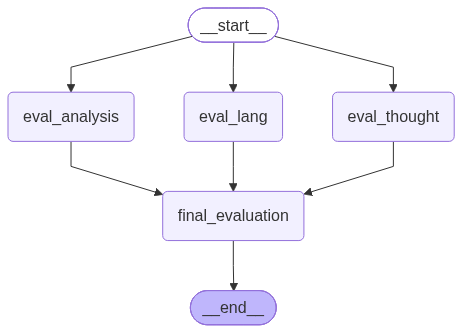

In [47]:
workflow

In [49]:
initial_state = {
    'essay': essay
}

workflow.invoke(initial_state)

{'essay': "Artificial Intelligence (AI) is transforming the world by changing how people live, work, learn, and communicate. From healthcare and education to agriculture and business, AI is becoming an essential part of modern society. For India, a country with a large population, a growing digital economy, and a strong technology sector, artificial intelligence presents an extraordinary opportunity to accelerate development and strengthen its position on the global stage.\n\nOne of the most promising applications of AI in India is in education and skill development. AI-powered learning platforms can provide personalized lessons based on students' abilities, helping them understand difficult concepts at their own pace. Students in rural areas can access educational resources that were previously unavailable to them. AI can also assist teachers in evaluating assignments and identifying students who need additional support. However, technology must complement teachers rather than replace

In [50]:
initial_state = {
    'essay': essay_2
}

workflow.invoke(initial_state)

{'essay': 'Artificial Intelligence are becoming one of the most important technology in todays world. It have changed the way people works, studies and communicate with others. India is a country with huge population and fast growing economy, AI can plays a important role in its development. However, there is also many challenges which India need to overcome.\n\nIn the field of education, AI have made learning more easier and accessible. Students can uses AI tools for solving questions, writing assignments and understanding difficult subjects. It also help teachers to prepare lessons and check students performance. But many students is becoming too dependent on these tools, which effect their creativity and thinking ability. If students only copy answers from AI, they will not learns how to solve problems by themselves.\n\nHealthcare is another sector where AI can brings major improvements. AI systems helps doctors to detect diseases and suggest suitable treatments. In rural areas, whe